# 5 - Nihai Deneyler (Düzeltilmiş)
Bu defter rapordaki **tüm sayıları ve grafikleri** tek seferde üretir.
Çalıştırmadan önce `1_data_preprocessing.ipynb` çalıştırılmış olmalı (`processed_train.csv`, `processed_test.csv`).

Notebook 3 ve 4'e göre düzeltmeler:
1. Gaussian ve G-Bell **aynı rastgele başlatma** ile başlar (adil karşılaştırma).
2. Kural ateşleme normalizasyonu **log uzayında softmax** ile yapılır (sıfıra bölme / çıktının 0'a çökmesi engellenir).
3. MSE'ye ek olarak **RMSE, MAE, R² ve eğitim süresi** kaydedilir.
4. YSA da 5 farklı seed ile çalıştırılır; **naif baseline** (eğitim ortalaması) eklenir.
5. Grafikler ve tablolar `../results/` altına kaydedilir.
6. Makalenin protokolü (log-seviye + rastgele bölme) ile bizim protokolün (log-fark + kronolojik) farkı ayrıca ölçülür.

In [1]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
DATA_DIR = "../data"
FIG_DIR = "../results/figures"
TAB_DIR = "../results/tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

SEEDS = range(5)          # 5 farklı rastgele tohum
FEATURES = ['GOLD_TL', 'VIX', 'BOND_2Y']

train_df = pd.read_csv(os.path.join(DATA_DIR, 'processed_train.csv'), index_col='Date', parse_dates=True)
test_df = pd.read_csv(os.path.join(DATA_DIR, 'processed_test.csv'), index_col='Date', parse_dates=True)
X_train, y_train = train_df[FEATURES].values, train_df['BIST100'].values
X_test, y_test = test_df[FEATURES].values, test_df['BIST100'].values
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

# Veri sağlık kontrolü (düz çizgi hatası tekrar oluşmasın)
assert len(train_df) == 550 and len(test_df) == 180, (len(train_df), len(test_df))
assert test_df['BIST100'].nunique() > 150, "Test hedefi neredeyse sabit: veri hatası var!"
print("Eğitim:", train_df.shape, "| Test:", test_df.shape)
print("Eğitim aralığı:", train_df.index[0].date(), "->", train_df.index[-1].date())
print("Test aralığı  :", test_df.index[0].date(), "->", test_df.index[-1].date())
print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

Eğitim: (550, 4) | Test: (180, 4)
Eğitim aralığı: 2010-01-15 -> 2020-07-24
Test aralığı  : 2020-07-31 -> 2024-01-05
torch 2.15.0+cpu | numpy 2.4.6 | pandas 3.1.0


In [2]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': float(np.sqrt(mse)),
            'MAE': mean_absolute_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}


class ANFIS(nn.Module):
    """Birinci dereceden Sugeno tipi ANFIS (kural başına bağımsız üyelik fonksiyonu).
    mf='gauss' : Gaussian  exp(-0.5*((x-c)/s)^2)
    mf='gbell' : G-Bell    1/(1+|(x-c)/a|^(2b))
    İki MF türü de AYNI rastgele başlatmayı kullanır (c, genişlik, sonuç parametreleri)."""

    def __init__(self, mf='gauss', num_inputs=3, num_rules=8):
        super().__init__()
        self.mf, self.R, self.D = mf, num_rules, num_inputs
        self.c = nn.Parameter(torch.rand(num_rules, num_inputs))             # merkez
        self.s = nn.Parameter(torch.rand(num_rules, num_inputs) + 0.1)       # sigma (gauss) / a (gbell)
        if mf == 'gbell':
            self.b = nn.Parameter(torch.full((num_rules, num_inputs), 1.2477))  # softplus(1.2477)+0.5 = 2.0
        self.cw = nn.Parameter(torch.rand(num_rules, num_inputs))            # sonuç katsayıları p,q,r
        self.cb = nn.Parameter(torch.rand(num_rules, 1))                     # sonuç sabiti s

    def width(self):
        return self.s.abs() + 1e-3

    def shape_b(self):
        return F.softplus(self.b) + 0.5

    def log_firing(self, x):                       # Katman 1+2: log uzayında çarpım T-normu
        z = (x.unsqueeze(1) - self.c.unsqueeze(0)) / self.width().unsqueeze(0)
        if self.mf == 'gauss':
            lm = -0.5 * z ** 2
        else:
            lm = -torch.log1p((z.abs() + 1e-8).pow(2 * self.shape_b().unsqueeze(0)))
        return lm.sum(dim=2)                       # (batch, kural)

    def forward(self, x):
        w = torch.softmax(self.log_firing(x), dim=1)          # Katman 3: normalizasyon
        f = x @ self.cw.T + self.cb.T                         # Katman 4: doğrusal sonuçlar
        return (w * f).sum(dim=1, keepdim=True)               # Katman 5: ağırlıklı toplam


def train_anfis(mf, rules, lr, epochs, seed, Xtr, ytr, Xte):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = ANFIS(mf, 3, rules)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    losses = []
    t0 = time.perf_counter()
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        loss = crit(model(Xtr), ytr)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    train_time = time.perf_counter() - t0
    model.eval()
    with torch.no_grad():
        preds = model(Xte).numpy().flatten()
    return model, preds, losses, train_time

## 1) Baseline modeller: Naif, Regresyon, YSA

In [3]:
rows, preds_store, models_store, loss_store = [], {}, {}, {}

# Naif baseline: eğitim ortalamasını sabit tahmin et
naive_pred = np.full(len(y_test), y_train.mean())
rows.append({'Model': 'Naif (eğitim ortalaması)', 'seed': 0, 'Süre': 0.0, **metrics(y_test, naive_pred)})

# Çoklu doğrusal regresyon (deterministik)
t0 = time.perf_counter()
lr_model = LinearRegression().fit(X_train, y_train)
lr_time = time.perf_counter() - t0
lr_pred = lr_model.predict(X_test)
rows.append({'Model': 'Çoklu doğrusal regresyon', 'seed': 0, 'Süre': lr_time, **metrics(y_test, lr_pred)})
preds_store['Regresyon'] = lr_pred
print("Regresyon katsayıları:", dict(zip(FEATURES, lr_model.coef_.round(3))), "| eğitim R²:", round(lr_model.score(X_train, y_train), 4))

# YSA: 1 gizli katman, 15 nöron, tanh (5 seed)
for seed in SEEDS:
    t0 = time.perf_counter()
    ann = MLPRegressor(hidden_layer_sizes=(15,), activation='tanh', solver='adam', max_iter=2000, random_state=seed)
    ann.fit(X_train, y_train)
    t = time.perf_counter() - t0
    p = ann.predict(X_test)
    rows.append({'Model': 'YSA (15 nöron, tanh)', 'seed': seed, 'Süre': t, **metrics(y_test, p)})
    if seed == 0:
        preds_store['YSA'] = p
print("Baseline modeller tamam.")

Regresyon katsayıları: {'GOLD_TL': np.float64(-0.096), 'VIX': np.float64(-0.324), 'BOND_2Y': np.float64(-0.8)} | eğitim R²: 0.2719
Baseline modeller tamam.


## 2) ANFIS ablation (A0–A4), 5 seed

In [4]:
CONFIGS = {
    'A0': dict(mf='gauss', rules=8,  lr=0.01,  ep=1500, name='A0: ANFIS (Gaussian, 8 kural)'),
    'A1': dict(mf='gbell', rules=8,  lr=0.01,  ep=1500, name='A1: yalnız G-Bell'),
    'A2': dict(mf='gauss', rules=16, lr=0.01,  ep=1500, name='A2: yalnız 16 kural'),
    'A3': dict(mf='gauss', rules=8,  lr=0.005, ep=2500, name='A3: yalnız lr 0,005 / 2500 epok'),
    'A4': dict(mf='gbell', rules=16, lr=0.005, ep=2500, name='A4: G-Bell, 16 kural, lr 0,005 / 2500 epok'),
}
for key, cfg in CONFIGS.items():
    print("Çalışıyor ->", cfg['name'])
    for seed in SEEDS:
        model, p, losses, t = train_anfis(cfg['mf'], cfg['rules'], cfg['lr'], cfg['ep'], seed, X_train_t, y_train_t, X_test_t)
        rows.append({'Model': cfg['name'], 'seed': seed, 'Süre': t, **metrics(y_test, p)})
        if seed == 0:
            preds_store[key], models_store[key], loss_store[key] = p, model, losses

runs = pd.DataFrame(rows)
runs.to_csv(os.path.join(TAB_DIR, 'all_runs.csv'), index=False)

order = ['Naif (eğitim ortalaması)', 'Çoklu doğrusal regresyon', 'YSA (15 nöron, tanh)'] + [c['name'] for c in CONFIGS.values()]
agg = runs.groupby('Model').agg(['mean', 'std'])
agg = agg.reindex(order)
table = pd.DataFrame(index=order)
for m, fmt in [('MSE', '{:.5f}'), ('RMSE', '{:.5f}'), ('MAE', '{:.5f}'), ('R2', '{:.4f}'), ('Süre', '{:.2f}')]:
    mean, std = agg[(m, 'mean')], agg[(m, 'std')].fillna(0)
    table[m] = ["{} ± {}".format(fmt.format(x), fmt.format(y)) if y > 0 else fmt.format(x) for x, y in zip(mean, std)]
table.index.name = 'Model'
table.to_csv(os.path.join(TAB_DIR, 'table1_all_models.csv'))
agg_flat = agg.copy(); agg_flat.columns = [f"{a}_{b}" for a, b in agg_flat.columns]
agg_flat.drop(columns=[c for c in agg_flat.columns if c.startswith('seed')]).to_csv(os.path.join(TAB_DIR, 'table1_numeric.csv'))
print("\nTABLO 1 - Test kümesi (180 hafta), ortalama ± std (5 seed)\n" + "=" * 78)
print(table.to_string())

# Tablo 2: A0 ile A4 karşılaştırması
t2 = []
for m in ['MSE', 'RMSE', 'MAE', 'R2', 'Süre']:
    a0, a4 = agg.loc[CONFIGS['A0']['name'], (m, 'mean')], agg.loc[CONFIGS['A4']['name'], (m, 'mean')]
    change = (a4 - a0) / abs(a0) * 100
    t2.append({'Ölçüt': m, 'Baseline (A0)': round(a0, 5), 'Önerilen (A4)': round(a4, 5), 'Değişim (%)': round(change, 2)})
t2 = pd.DataFrame(t2)
t2.to_csv(os.path.join(TAB_DIR, 'table2_A0_vs_A4.csv'), index=False)
print("\nTABLO 2 - Baseline (A0) vs Önerilen (A4)\n" + "=" * 78)
print(t2.to_string(index=False))

Çalışıyor -> A0: ANFIS (Gaussian, 8 kural)
Çalışıyor -> A1: yalnız G-Bell
Çalışıyor -> A2: yalnız 16 kural
Çalışıyor -> A3: yalnız lr 0,005 / 2500 epok
Çalışıyor -> A4: G-Bell, 16 kural, lr 0,005 / 2500 epok

TABLO 1 - Test kümesi (180 hafta), ortalama ± std (5 seed)
                                                          MSE               RMSE                MAE                R2         Süre
Model                                                                                                                             
Naif (eğitim ortalaması)                              0.03444            0.18557            0.14648           -0.0467         0.00
Çoklu doğrusal regresyon                              0.04773            0.21847            0.15055           -0.4506         0.00
YSA (15 nöron, tanh)                        0.05069 ± 0.01979  0.22211 ± 0.04124  0.16918 ± 0.03204  -0.5407 ± 0.6014  0.03 ± 0.01
A0: ANFIS (Gaussian, 8 kural)               0.04905 ± 0.00442  0.22130 ± 0.00

## 3) Grafikler (Şekil 1-3)

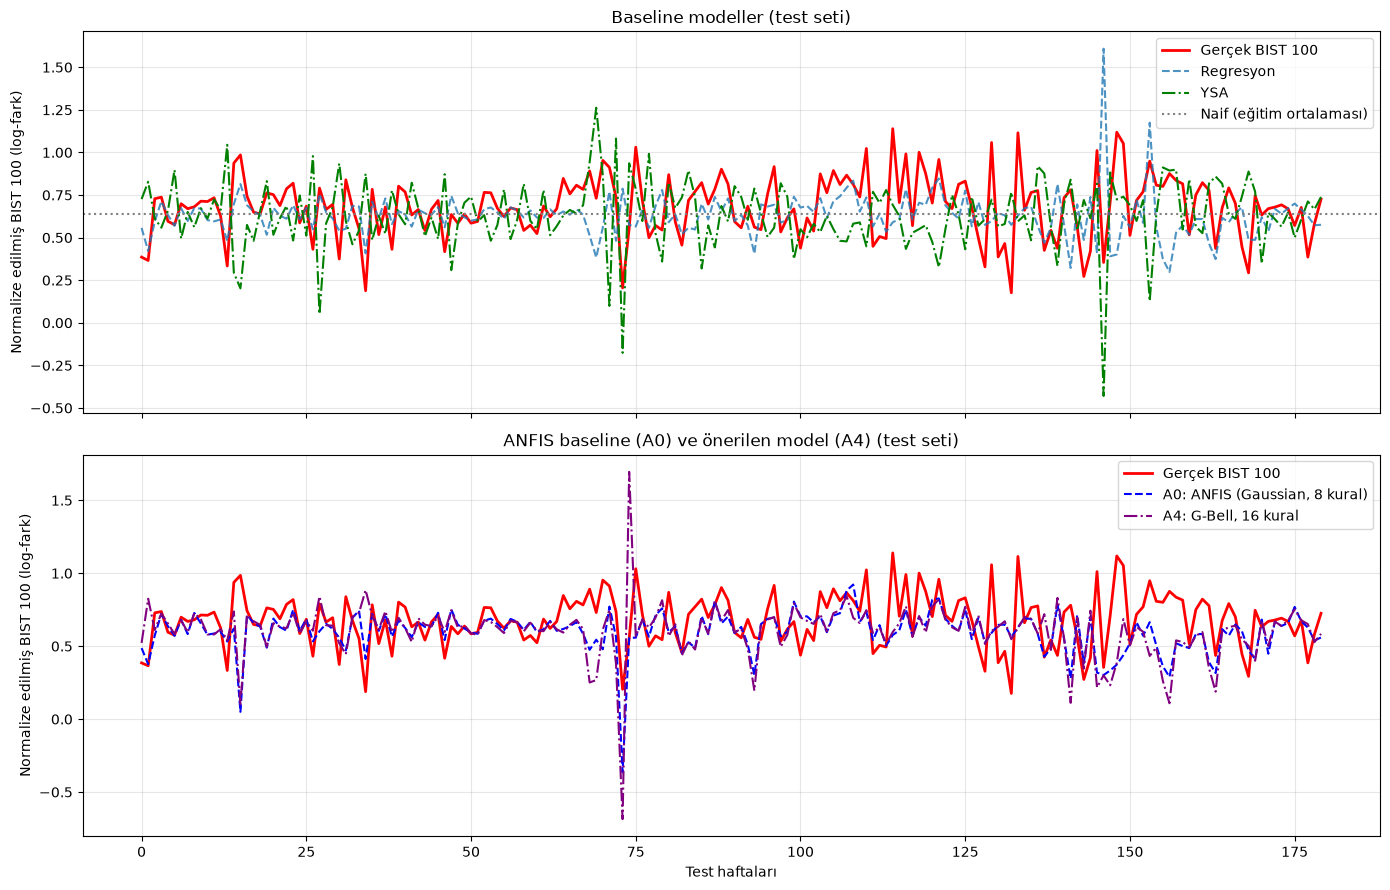

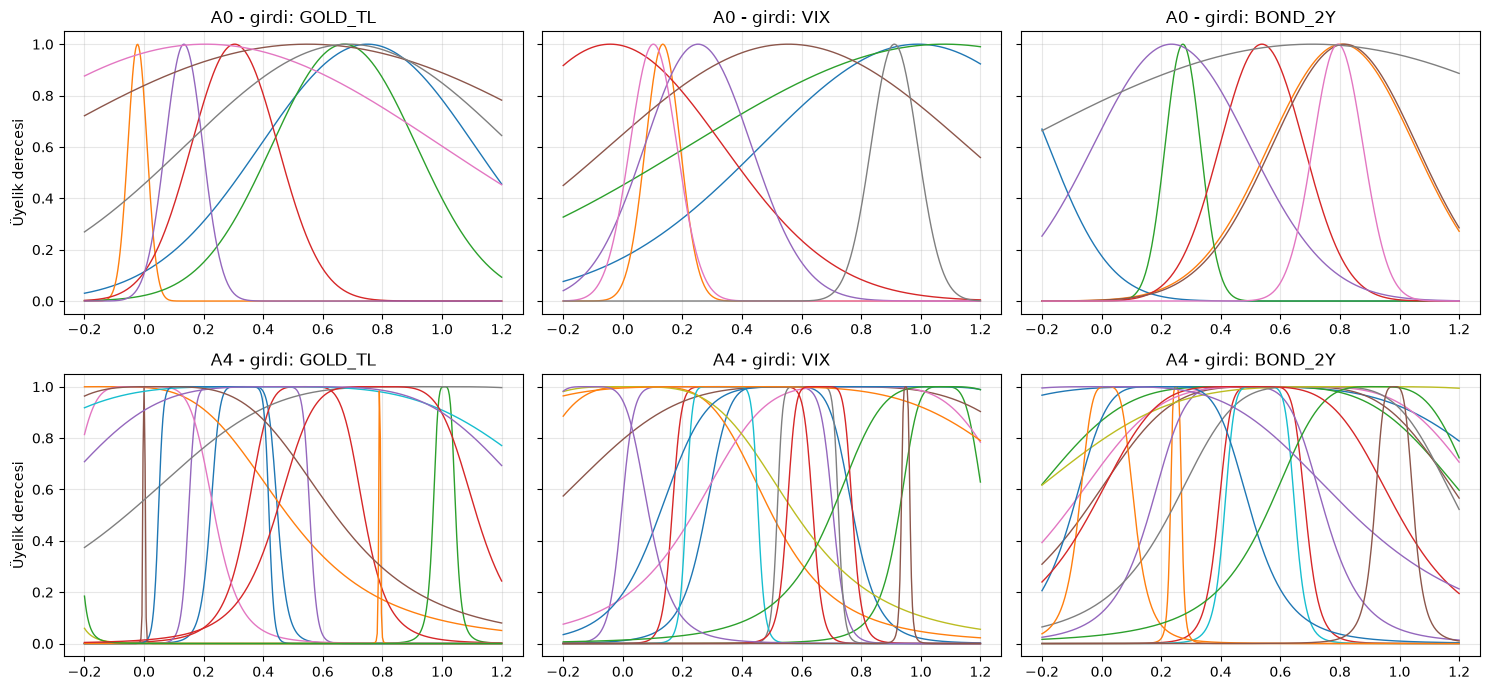

A4 öğrenilen G-Bell eğim (b): ort=3.024, min=1.835, maks=11.461 (başlangıç 2.0)


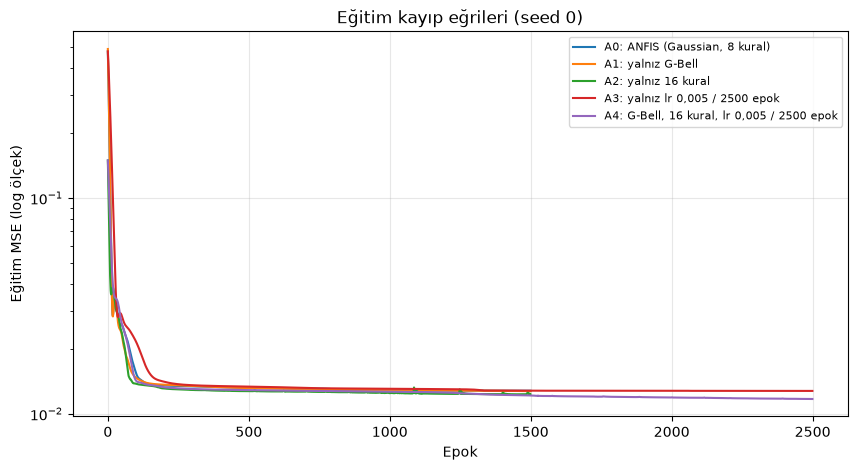

In [5]:
# Şekil 1: tüm modellerin tahmini (seed 0)
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(y_test, color='red', lw=2, label='Gerçek BIST 100')
axes[0].plot(preds_store['Regresyon'], '--', alpha=.8, label='Regresyon')
axes[0].plot(preds_store['YSA'], '-.', color='green', label='YSA')
axes[0].axhline(y_train.mean(), color='gray', ls=':', label='Naif (eğitim ortalaması)')
axes[0].set_title('Baseline modeller (test seti)'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(y_test, color='red', lw=2, label='Gerçek BIST 100')
axes[1].plot(preds_store['A0'], '--', color='blue', label='A0: ANFIS (Gaussian, 8 kural)')
axes[1].plot(preds_store['A4'], '-.', color='purple', label='A4: G-Bell, 16 kural')
axes[1].set_title('ANFIS baseline (A0) ve önerilen model (A4) (test seti)'); axes[1].legend(); axes[1].grid(alpha=.3)
axes[1].set_xlabel('Test haftaları')
for ax in axes: ax.set_ylabel('Normalize edilmiş BIST 100 (log-fark)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'fig1_all_models.png'), dpi=300, bbox_inches='tight'); plt.show()

# Şekil 2: öğrenilmiş üyelik fonksiyonları (A0 ve A4, seed 0)
xs = np.linspace(-0.2, 1.2, 400)
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for r, key in enumerate(['A0', 'A4']):
    m = models_store[key]
    c, w = m.c.detach().numpy(), m.width().detach().numpy()
    b = m.shape_b().detach().numpy() if m.mf == 'gbell' else None
    for d in range(3):
        for k in range(m.R):
            mu = np.exp(-0.5 * ((xs - c[k, d]) / w[k, d]) ** 2) if b is None else 1 / (1 + np.abs((xs - c[k, d]) / w[k, d]) ** (2 * b[k, d]))
            axes[r, d].plot(xs, mu, lw=1)
        axes[r, d].set_title(f"{CONFIGS[key]['name'].split(':')[0]} - girdi: {FEATURES[d]}"); axes[r, d].grid(alpha=.3)
    axes[r, 0].set_ylabel('Üyelik derecesi')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'fig2_membership_functions.png'), dpi=300, bbox_inches='tight'); plt.show()
bvals = models_store['A4'].shape_b().detach().numpy()
print(f"A4 öğrenilen G-Bell eğim (b): ort={bvals.mean():.3f}, min={bvals.min():.3f}, maks={bvals.max():.3f} (başlangıç 2.0)")

# Şekil 3: eğitim kayıp eğrileri
plt.figure(figsize=(10, 5))
for key in CONFIGS:
    plt.plot(loss_store[key], label=CONFIGS[key]['name'])
plt.yscale('log'); plt.xlabel('Epok'); plt.ylabel('Eğitim MSE (log ölçek)'); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title('Eğitim kayıp eğrileri (seed 0)')
plt.savefig(os.path.join(FIG_DIR, 'fig3_loss_curves.png'), dpi=300, bbox_inches='tight'); plt.show()

## 4) Makale protokolü ile karşılaştırma
Makale: log-**seviye** + 0-1 ölçekleme + **rastgele** 540/180 bölme.
Bizim çalışma: log-**fark** + **kronolojik** bölme. Aynı modeller üç protokolde denenir.

In [6]:
RAW_FILES = {"BIST100": "bist100_weekly.csv", "VIX": "vix_weekly.csv",
             "GOLD_TL": "gold_tl_weekly.csv", "BOND_2Y": "bond_2y_weekly.csv"}


def parse_num(v):
    if pd.isna(v):
        return np.nan
    s = re.sub(r'[^\d.,\-]', '', str(v).strip())
    if not s:
        return np.nan
    if '.' in s and ',' in s:
        s = s.replace('.', '').replace(',', '.') if s.rfind(',') > s.rfind('.') else s.replace(',', '')
    elif ',' in s:
        s = s.replace(',', '.')
    # Not: Altın/TL'de '1.69' ve '1.707' gibi değerler BİN TL cinsinden ondalık olarak okunur (ölçek log-farkta etkisizdir)
    try:
        return float(s)
    except ValueError:
        return np.nan


def load_raw(file_name, col):
    df = pd.read_csv(os.path.join(DATA_DIR, file_name), encoding='utf-8-sig')
    df = df.iloc[:, [0, 1]].copy()
    df.columns = ['Date', col]
    df['Date'] = pd.to_datetime(df['Date'], format='%d.%m.%Y', errors='coerce')
    df[col] = df[col].apply(parse_num)
    return df.dropna().set_index('Date').sort_index()


def prep_log_levels():
    dfs = [load_raw(f, k) for k, f in RAW_FILES.items()]
    df = pd.concat(dfs, axis=1, sort=True).resample('W-FRI').last().ffill(limit=2).dropna()
    return np.log(df)[FEATURES + ['BIST100']]


def run_protocol(name, df_log, split, seeds=(0, 1, 2), n_test=180):
    n = len(df_log)
    if split == 'random':
        idx = np.random.RandomState(42).permutation(n)
        te_idx, tr_idx = np.sort(idx[:n_test]), np.sort(idx[n_test:])
    else:
        tr_idx, te_idx = np.arange(n - n_test), np.arange(n - n_test, n)
    tr, te = df_log.iloc[tr_idx], df_log.iloc[te_idx]
    sc = MinMaxScaler().fit(tr)
    trs, tes = sc.transform(tr), sc.transform(te)
    Xtr, ytr, Xte, yte = trs[:, :3], trs[:, 3], tes[:, :3], tes[:, 3]
    out = []
    out.append({'Protokol': name, 'Model': 'Regresyon', **metrics(yte, LinearRegression().fit(Xtr, ytr).predict(Xte))})
    res = [metrics(yte, MLPRegressor(hidden_layer_sizes=(15,), activation='tanh', max_iter=2000, random_state=s).fit(Xtr, ytr).predict(Xte)) for s in seeds]
    out.append({'Protokol': name, 'Model': 'YSA', **{k: np.mean([r[k] for r in res]) for k in res[0]}})
    Xtr_t, ytr_t = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xte_t = torch.tensor(Xte, dtype=torch.float32)
    res = [metrics(yte, train_anfis('gauss', 8, 0.01, 1500, s, Xtr_t, ytr_t, Xte_t)[1]) for s in seeds]
    out.append({'Protokol': name, 'Model': 'ANFIS (A0)', **{k: np.mean([r[k] for r in res]) for k in res[0]}})
    return out


df_log = prep_log_levels()
print("Ham seviye verisi:", df_log.shape, df_log.index[0].date(), "->", df_log.index[-1].date())
proto = []
proto += run_protocol('P1: log-seviye, rastgele bölme (makale benzeri)', df_log, 'random')
proto += run_protocol('P2: log-seviye, kronolojik bölme', df_log, 'chrono')
# P3: bizim ana protokol (log-fark, kronolojik) -> Tablo 1'den
for label, name in [('Regresyon', 'Çoklu doğrusal regresyon'), ('YSA', 'YSA (15 nöron, tanh)'), ('ANFIS (A0)', CONFIGS['A0']['name'])]:
    proto.append({'Protokol': 'P3: log-fark, kronolojik (bu çalışma)', 'Model': label,
                  **{k: runs[runs.Model == name][k].mean() for k in ['MSE', 'RMSE', 'MAE', 'R2']}})
proto = pd.DataFrame(proto).round(5)
proto.to_csv(os.path.join(TAB_DIR, 'table4_protocol_comparison.csv'), index=False)
print("\nTABLO 4 - Protokol karşılaştırması (test seti)\n" + "=" * 78)
print(proto.to_string(index=False))
print("\nBitti. Sonuçlar ../results/tables ve ../results/figures klasörlerinde.")

Ham seviye verisi: (731, 4) 2010-01-08 -> 2024-01-05

TABLO 4 - Protokol karşılaştırması (test seti)
                                       Protokol      Model     MSE    RMSE     MAE       R2
P1: log-seviye, rastgele bölme (makale benzeri)  Regresyon 0.00588 0.07665 0.05769  0.88240
P1: log-seviye, rastgele bölme (makale benzeri)        YSA 0.01060 0.10245 0.07580  0.78782
P1: log-seviye, rastgele bölme (makale benzeri) ANFIS (A0) 0.00144 0.03798 0.03007  0.97112
               P2: log-seviye, kronolojik bölme  Regresyon 0.64854 0.80532 0.63271 -0.20396
               P2: log-seviye, kronolojik bölme        YSA 0.99661 0.99763 0.78520 -0.85011
               P2: log-seviye, kronolojik bölme ANFIS (A0) 1.27489 1.07373 0.85656 -1.36671
          P3: log-fark, kronolojik (bu çalışma)  Regresyon 0.04773 0.21847 0.15055 -0.45064
          P3: log-fark, kronolojik (bu çalışma)        YSA 0.05069 0.22211 0.16918 -0.54074
          P3: log-fark, kronolojik (bu çalışma) ANFIS (A0) 0.04905 0.22